In [239]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
import scipy.constants as const
import statistics

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern'],
    })
plt.rcParams.update({'font.size': 20})

In [159]:
def dE(S,J,H,i,j):
    E = -2*J*S[i,j]* (S[i-1,j]+S[i+1,j]+S[i,j-1]+S[i,j+1]) + 2*H*S[i,j]
    return E #razlika energije zaradi premika spina delčka na i,j
def E(S,J,H):
    E=0
    for i in range(len(S)-1):
        for j in range(len(S[0])-1):
            #for jx in range(len(S)-1):
            #    for jy in range(len(S[0])-1):
            #       E -= J*S[ix,iy]*S[jx,jy]
            for k in range(-1,2,2):
                E -= J*S[i,j]*S[i+k,j] + J*S[i,j]*S[i,j+k]
    # for i in range(len(S)):
    #     for j in range(len(S[0])):
    #         E += H*S[i,j]
    E += H * np.sum(S)
    return E #cela energija
def dE_per(S,J,H,i,j):
    '''periodični RP'''
    i_1=i-1
    i_2=i+1
    j_1=j-1
    j_2=j+1
    if i==0:
        i_1 = len(S)-1
    if j==0:
        j_1 = len(S)-1
    if i_2==len(S):
        i_2 = 0
    if j_2==len(S):
        j_2 = 0
    E = -2*J*S[i,j]* (S[i_1,j]+S[i_2,j]+S[i,j_1]+S[i,j_2]) + 2*H*S[i,j]
    return E #razlika energije zaradi premika spina delčka na i,j

In [286]:
def magnetizacija(S,N):
    return 1/N * np.sum(S)
def suscept(vrednosti,N,T):
    '''susceptibilnost (vrednost = M - magnetizacija)'''
    return (np.average(vrednosti**2) - np.average(np.abs(vrednosti))**2) / (N*const.k*T)
def spec_topl(vrednosti,N,T):
    '''spec. toplota (vrednost = E - varianca energije po burn-inu)'''
    #return (np.average(vrednosti**2) - np.average(np.abs(vrednosti))**2) / (N*const.k*T**2)
    return statistics.variance(vrednosti)/N/const.k/T**2

In [161]:
def metropolis(energija, S,T,J,H):
    '''J=1 feromagnet, H=0 ni zunanjega polja;
    robnih točk se ne upošteva'''
    S_old = S.copy()
    i,j = np.random.randint(1, len(S)-1, size=2) #ni robmih točk
    if S[i,j] == 0:
        premik = np.random.randint(0,2)
        if premik == 0:
            S[i,j] -= 1
        else:
            S[i,j] += 1
    else: #je -1 ali 1
        S[i,j] = -S[i,j]
    E_spr = dE(S,J,H,i,j)
    energija_nova = energija + E_spr
    if E_spr > 0:
        u=np.random.random()
        if u > np.exp(-E_spr/T):
            S = S_old
            energija_nova = energija
            metropolis.counter +=1
    return S, energija_nova
def metropolis_per(energija, S,T,J,H):
    '''J=1 feromagnet, H=0 ni zunanjega polja;
    periodični RP'''
    S_old = S.copy()
    i,j = np.random.randint(0, len(S), size=2)#vse
    if S[i,j] == 0:
        premik = np.random.randint(0,2)
        if premik == 0:
            S[i,j] -= 1
        else:
            S[i,j] += 1
    else: #je -1 ali 1
        S[i,j] = -S[i,j]    
    E_spr = dE_per(S,J,H,i,j)
    energija_nova = energija + E_spr
    if E_spr > 0:
        u=np.random.random()
        if u > np.exp(-E_spr/T):
            S = S_old
            energija_nova = energija
            metropolis.counter +=1
    return S, energija_nova

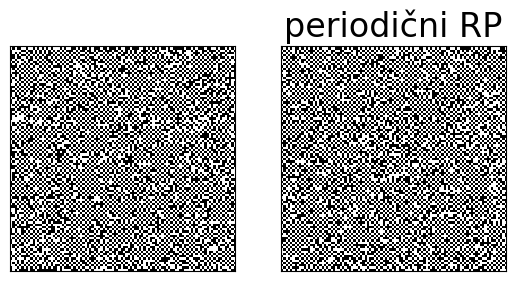

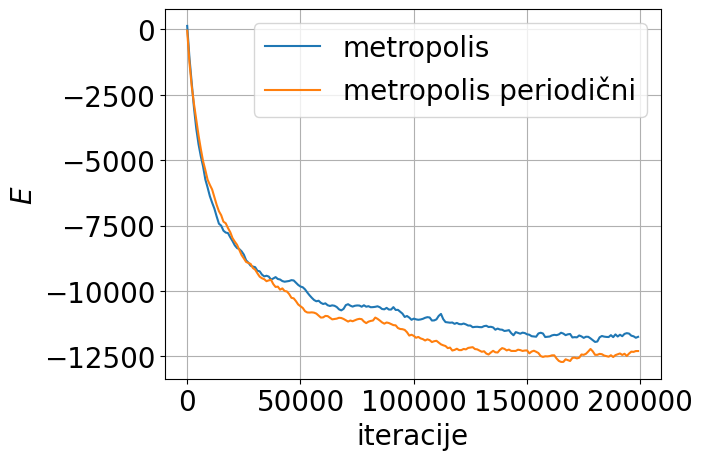

In [270]:
n = 100
n_iter = 200000
n_write = 1000 #na koliko iteracij se zapiše energija
T = 1
J=-1
H=0
T0=[2.27]
for T in T0 :
    fig, ax = plt.subplots(1,2)
    #S=np.full(n**2,1).reshape(n,n) #vse enako
    S=np.random.randint(-1,1,(n,n)) #naključni ZP
    S[S==0] = 1
    i_e=0
    metropolis.counter = 0
    en_metr = E(S,J,H)
    energija=np.zeros(n_iter//n_write)
    energija_metropolis=np.zeros(n_iter//n_write)
    for i in range(n_iter):
        S, en_metr = metropolis(en_metr, S,T,J,H)
        if i % n_write==0:
            #energija[i_e] = E(S,J,H)
            energija_metropolis[i_e] = en_metr
            i_e+=1
    n_rej1 = metropolis.counter
    ax[0].imshow(S, cmap='gray', interpolation='nearest')
    #plt.colorbar()
    ax[0].set_xticks([])
    ax[0].set_yticks([])
    #plt.show()

    S=np.random.randint(-1,1,(n,n))
    S[S==0] = 1
    i_e=0
    metropolis.counter = 0
    en_metr = E(S,J,H)
    energija_per=np.zeros(n_iter//n_write)
    energija_metropolis_per=np.zeros(n_iter//n_write)
    for i in range(n_iter):
        S,en_metr = metropolis_per(en_metr, S,T,J,H)
        if i % n_write==0:
            #energija_per[i_e] = E(S,J,H)
            energija_metropolis_per[i_e] = en_metr
            i_e+=1
    n_rej2 = metropolis.counter
    ax[1].imshow(S, cmap='gray', interpolation='nearest')
    plt.xticks([])
    plt.yticks([])
    plt.title(f'periodični RP')
    #plt.savefig(f'slike/metopolis_T_{T}.pdf', bbox_inches='tight')
    plt.show()

x_val=[n_write*i for i in range(n_iter//n_write)]
#plt.plot(x_val, energija, label='osnovni')
plt.plot(x_val, energija_metropolis, label='metropolis')
#plt.plot(x_val, energija_per, label='periodicni RP')
plt.plot(x_val, energija_metropolis_per, label='metropolis periodični')
plt.legend()
plt.grid()
plt.xlabel('iteracije')
plt.ylabel('$E$')
#plt.savefig(f'slike/metopolis_potek_E.pdf', bbox_inches='tight')

T(1/10) = 0.01°C
T(2/10) = 0.51°C
T(3/10) = 1.01°C
T(4/10) = 1.51°C
T(5/10) = 2.01°C
T(6/10) = 2.51°C
T(7/10) = 3.01°C
T(8/10) = 3.51°C
T(9/10) = 4.01°C
T(10/10) = 4.51°C


Text(0, 0.5, '$\\langle M \\rangle$')

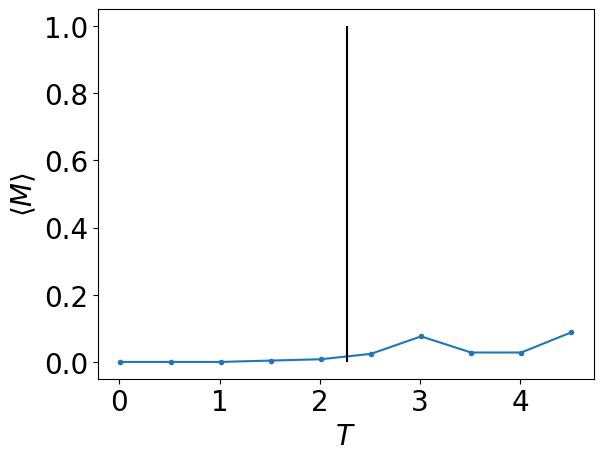

In [163]:
n = 10
n_iter = 5000
n_ponovitev = 5
temp = np.arange(0.01,5,0.5)
J=-1
H=0

metropolis.counter = 0
#energija=np.zeros(n_iter//n_write)
M=np.zeros((len(temp),n_ponovitev))
Ti=0
for T in temp:
    print(f'T({Ti+1}/{len(temp)}) = {T}°C')
    for j in range(n_ponovitev):
        #print(j+1, '/',n_ponovitev)
        S=np.random.randint(-1,1,(n,n))
        S[S==0] = 1
        en_metr = E(S,J,H)
        for i in range(n_iter):
            S, en_metr = metropolis_per(en_metr, S,T,J,H)
        M[Ti,j] = magnetizacija(S, n**2)
        #print(M[Ti,j])
    Ti+=1
# plt.imshow(S, cmap='gray', interpolation='nearest')
# plt.xticks([])
# plt.yticks([])
# plt.title(f'$T=${T}°C')
# plt.show()

M_avg = [np.average(np.abs(i)) for i in M]
plt.plot(temp, M_avg,'.-')
plt.vlines(2.269185,0,1,'k')
plt.xlabel('$T$')
plt.ylabel('$\langle M \\rangle$')
#plt.savefig('slike/magnetizacija.pdf', bbox_inches='tight')

In [164]:
def mag_T(n,n_iter,n_ponovitev, temp,J,H):
    metropolis.counter = 0
    M=np.zeros((len(temp),n_ponovitev))
    Ti=0
    for T in temp:
        #print(f'T({Ti+1}/{len(temp)}) = {T}°C')
        for j in range(n_ponovitev):
            #print(j+1, '/',n_ponovitev)
            S=np.random.randint(-1,1,(n,n))
            S[S==0] = 1
            en_metr = E(S,J,H)
            for i in range(n_iter):
                S, en_metr = metropolis_per(en_metr, S,T,J,H)
            M[Ti,j] = magnetizacija(S, n**2)
            #print(M[Ti,j])
        Ti+=1
    M_avg = [np.average(np.abs(i)) for i in M]
    return M_avg

H = 0.2
H = 0.4
H = 0.6000000000000001
H = 0.8


KeyboardInterrupt: 

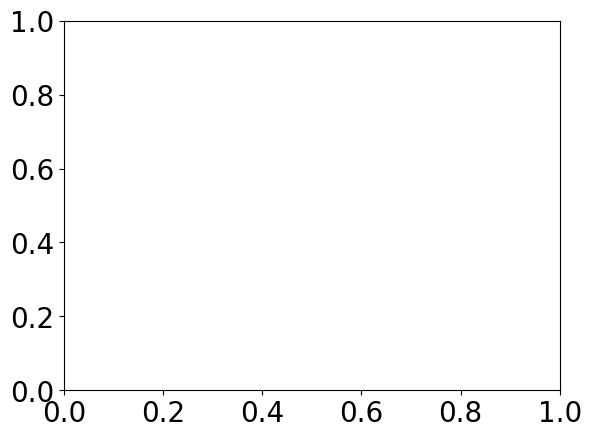

In [165]:
M=[]
H0=np.arange(0,1.5,0.2)
cmap = plt.get_cmap('viridis')
fig, ax = plt.subplots(1,1)
for H in H0[1::]: #čudno blizu 0
    n = 10
    n_iter = 10000
    n_ponovitev = 10
    temp = np.arange(0.01,7,0.5)
    J=1
    print('H =',H)
    Mi = mag_T(n,n_iter,n_ponovitev,temp,J,H)
    M.append(Mi)
for i in range(len(M)):
    color_i = cmap(H0[i+1] / max(H0)) ###
    ax.plot(temp,M[i], '.-',label=str(round(H0[i],1)), color=color_i)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=min(H0), vmax=max(H0)))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', label='zunanje polje')
cbar.ax.yaxis.set_label_coords(5, 0.5)
#plt.legend()
plt.vlines(2.269185,0,1,'k')
plt.xlabel('$T$')
plt.ylabel('$\langle M \\rangle$')
#plt.savefig('slike/vpliv_H_magnetizacija.pdf', bbox_inches='tight')

n = 10
n = 20
n = 30
n = 40


Text(0, 0.5, '$\\langle M \\rangle$')

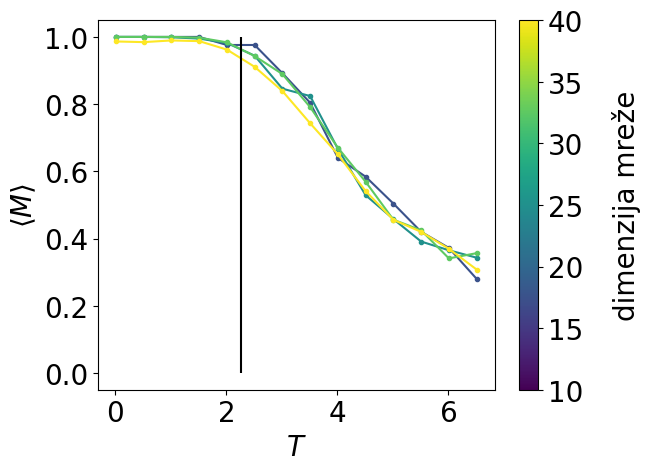

In [166]:
M=[]
n0=np.arange(10,50,10)
cmap = plt.get_cmap('viridis')
fig, ax = plt.subplots(1,1)
for n in n0:
    n = int(n)
    n_iter = 10000
    n_ponovitev = 5
    temp = np.arange(0.01,7,0.5)
    J=1
    H=1
    print('n =',n)
    Mi = mag_T(n,n_iter,n_ponovitev,temp,J,H)
    M.append(Mi)
for i in range(len(M)):
    color_i = cmap(n0[i] / max(n0))
    ax.plot(temp,M[i], '.-',color=color_i)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=min(n0), vmax=max(n0)))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', label='dimenzija mreže')
cbar.ax.yaxis.set_label_coords(5, 0.5)
#plt.legend()
plt.vlines(2.269185,0,1,'k')
plt.xlabel('$T$')
plt.ylabel('$\langle M \\rangle$')
#plt.savefig('slike/vpliv_n_magnetizacija_H1.pdf', bbox_inches='tight')

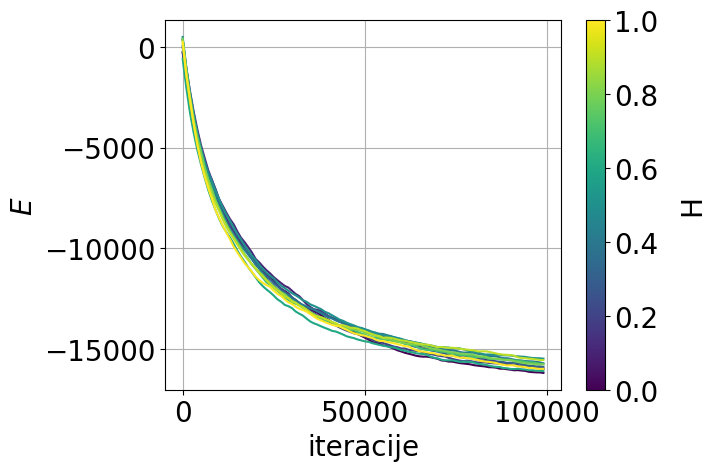

In [265]:
n = 100
n_iter = 100000
n_write = 1000 #na koliko iteracij se zapiše energija
T = 1
J=-1
H0=np.arange(0,1.1,0.1)
cmap = plt.get_cmap('viridis')
fig, ax = plt.subplots(1,1)
energija = []
for H in H0:
    S=np.random.randint(-1,1,(n,n))
    S[S==0] = 1
    i_e=0
    metropolis.counter = 0
    en_metr = E(S,J,H)
    energija_per=np.zeros(n_iter//n_write)
    energija_metropolis_per=np.zeros(n_iter//n_write)
    for i in range(n_iter):
        S,en_metr = metropolis_per(en_metr, S,T,J,H)
        if i % n_write==0:
            energija_metropolis_per[i_e] = en_metr
            i_e+=1
    n_rej2 = metropolis.counter
    energija.append(energija_metropolis_per)

x_val=[n_write*i for i in range(n_iter//n_write)]
for i in range(len(energija)):
    color_i = cmap(H0[i] / max(H0))
    plt.plot(x_val, energija[i], label='metropolis periodični', color=color_i)
#plt.legend()
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=min(H0), vmax=max(H0)))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', label='H')
cbar.ax.yaxis.set_label_coords(5, 0.5)
plt.grid()
plt.xlabel('iteracije')
plt.ylabel('$E$')
#plt.savefig(f'slike/metopolis_E_H.pdf', bbox_inches='tight')

Text(0, 0.5, '$E$')

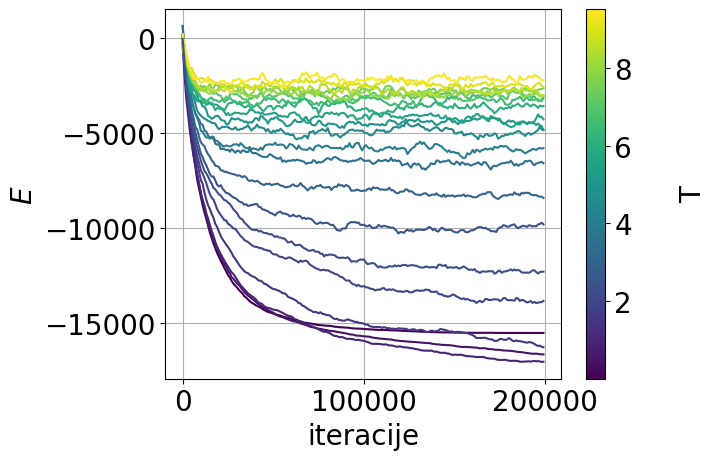

In [261]:
n = 100
n_iter = 200000
n_write = 1000 #na koliko iteracij se zapiše energija
T = 1
J=-1
H=0.5
T0=np.arange(0.01,10,0.5)
T0=np.append(T0,2.27)
cmap = plt.get_cmap('viridis')
fig, ax = plt.subplots(1,1)
energija = []
for T in T0:
    S=np.random.randint(-1,1,(n,n))
    S[S==0] = 1
    i_e=0
    metropolis.counter = 0
    en_metr = E(S,J,H)
    energija_per=np.zeros(n_iter//n_write)
    energija_metropolis_per=np.zeros(n_iter//n_write)
    for i in range(n_iter):
        S,en_metr = metropolis_per(en_metr, S,T,J,H)
        if i % n_write==0:
            energija_metropolis_per[i_e] = en_metr
            i_e+=1
    n_rej2 = metropolis.counter
    energija.append(energija_metropolis_per)

for i in energija:
    n_min=list(i).count(min(i))
    #print(min(i), n_min)

x_val=[n_write*i for i in range(n_iter//n_write)]
for i in range(len(energija)):
    color_i = cmap(T0[i] / max(T0))
    plt.plot(x_val, energija[i], label='metropolis periodični', color=color_i)
#plt.legend()
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=min(T0), vmax=max(T0)))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', label='T')
cbar.ax.yaxis.set_label_coords(5, 0.5)
plt.grid()
plt.xlabel('iteracije')
plt.ylabel('$E$')
#plt.savefig(f'slike/metopolis_E_T.pdf', bbox_inches='tight')

Text(0.5, 0, '$E$')

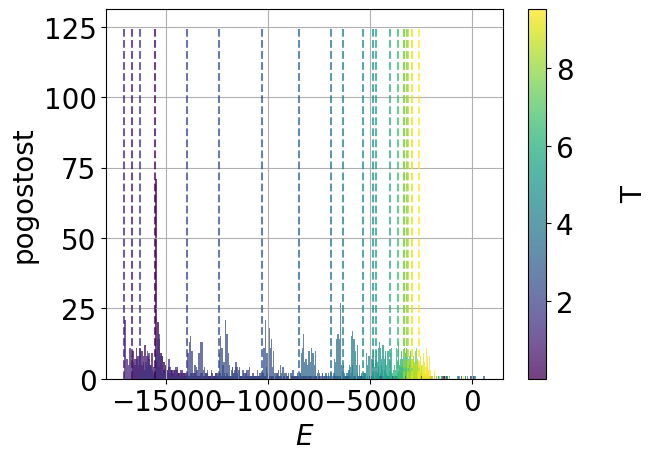

In [262]:
cmap = plt.get_cmap('viridis')
fig, ax = plt.subplots(1,1)
for i in range(len(energija)):
    color_i = cmap(T0[i] / max(T0))
    ax.hist(energija[i],color=color_i, bins=200,alpha=0.75)
    ax.vlines(min(energija[i]),0,125, linestyle='--', color=color_i,alpha=0.75)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=min(T0), vmax=max(T0)))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', label='T',alpha=0.75)
cbar.ax.yaxis.set_label_coords(5, 0.5)
plt.grid()
plt.ylabel('pogostost')
plt.xlabel('$E$')
#plt.savefig(f'slike/metopolis_porazd_E.pdf', bbox_inches='tight')

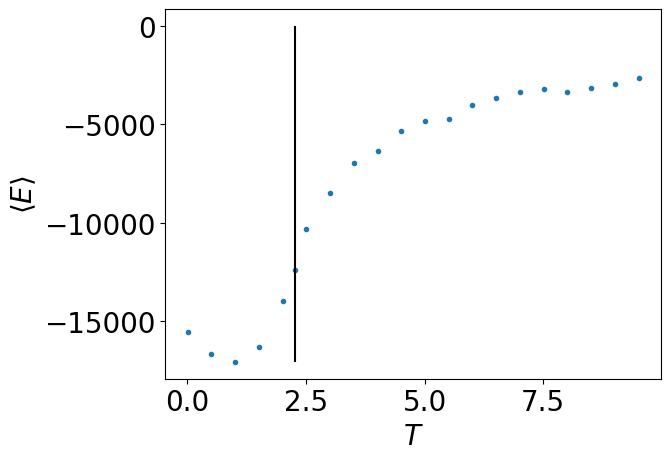

In [264]:
er=[]
for i in energija:
    er.append(min(i))
plt.plot(T0, er,'.')
plt.vlines(2.27,0,min(er),'k')
plt.xlabel('$T$')
plt.ylabel('$\langle E \\rangle$')
#plt.savefig(f'slike/metopolis_E_T_odv_J.pdf', bbox_inches='tight')

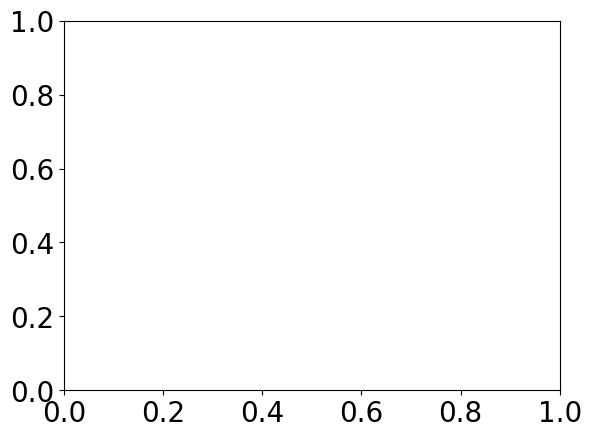

In [242]:
n = 100
n_iter = 200000
n_write = 1000 #na koliko iteracij se zapiše energija
N=10
T = 1
J=1
H=0.5
cmap = plt.get_cmap('viridis')
fig, ax = plt.subplots(1,1)
energija = []
for _ in range(N):
    S=np.random.randint(-1,1,(n,n))
    S[S==0] = 1
    i_e=0
    metropolis.counter = 0
    en_metr = E(S,J,H)
    energija_metropolis_per=np.zeros(n_iter//n_write)
    for i in range(n_iter):
        S,en_metr = metropolis_per(en_metr, S,T,J,H)
        if i % n_write==0:
            energija_metropolis_per[i_e] = en_metr
            i_e+=1
    n_rej2 = metropolis.counter
    energija.append(energija_metropolis_per)

In [246]:
energija = np.array(energija)
e_r=[]
for i in energija:
    er=[]
    for j in i:
        er.append(np.min(j))
    e_r.append(er)

2.1166724061251056e+30
7.933337122823926e+26
2.08587967879891e+26
8.995972040603006e+25
5.065234401626361e+25
3.248958413811855e+25
2.4162241704850684e+25
1.7655706813025928e+25
1.3068043632541773e+25
1.0280451967335046e+25


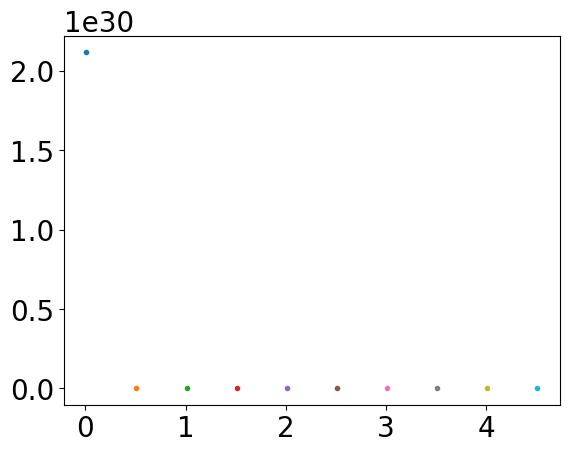

In [250]:
e_r=np.array(e_r)
for i in range(len(e_r)):
    topl = spec_topl(e_r[i],n**2,T0[i])
    print(topl)
    plt.plot(T0[i],topl,'.')

In [294]:
def magnetizacija_(matrika):
    vsota = 0
    for vrsta in range(len(matrika)):
        for stolpec in range(len(matrika[0])):
            vsota += matrika[vrsta][stolpec]
    return vsota / ((len(matrika)) ** 2)
def magnetizacija_kvadrat_(matrika):
    vsota = 0
    for vrsta in range(len(matrika)):
        for stolpec in range(len(matrika[0])):
            vsota += matrika[vrsta][stolpec]**2
    return vsota / ((len(matrika)) ** 2)
def susceptibilnost_(mreza,temperatura):
    return (magnetizacija_kvadrat_(mreza)-magnetizacija_(mreza)**2)/temperatura

def energija_(mreza):
    N=len(mreza)
    vsota=0
    for i in range(len(mreza)):
        for j in range(len(mreza)):
            vsota+=-(mreza[i][pbc_(j+1,N)]+mreza[i][pbc_(j-1,N)]+mreza[pbc_(i+1,N)][j]+mreza[pbc_(i-1,N)][j])*mreza[i][j]
    return vsota/(len(mreza))**2
def energija_kvadrat_(mreza):
    vsota=0
    N=len(mreza)
    for i in range(N):
        for j in range(len(mreza)):
            vsota+=(-(mreza[i][pbc_(j+1,N)]+mreza[i][pbc_(j-1,N)]+mreza[pbc_(i+1,N)][j]+mreza[pbc_(i-1,N)][j])*mreza[i][j])**2
    return vsota/(len(mreza))**2
def kapaciteta_(mreza,temperatura):
    return (energija_kvadrat_(mreza)-energija_(mreza)**2)/(temperatura**2)
def pbc_(i,velikost):
    if i>=velikost:
        return 0
    if i<0:
        return velikost-1
    else:
        return i
def ising_(N,temperatura):
    mreza=[ [ 1 for i in range(N)] for j in range(N)]
    mcs=0
    while (mcs<200):
        for i in range(N):
            for j in range(N):
                # print(j,i)
                # print(pbc(j,N),pbc(i,N))
                delta=-1*(mreza[i][pbc_(j+1,N)]+mreza[i][pbc_(j-1,N)]+mreza[pbc_(i+1,N)][j]+mreza[pbc_(i-1,N)][j])*mreza[i][j]
                #print(delta)
                if np.random.rand()<np.exp(2*delta/temperatura):
                    mreza[i][j]*=-1
        mcs+=1
    return mreza

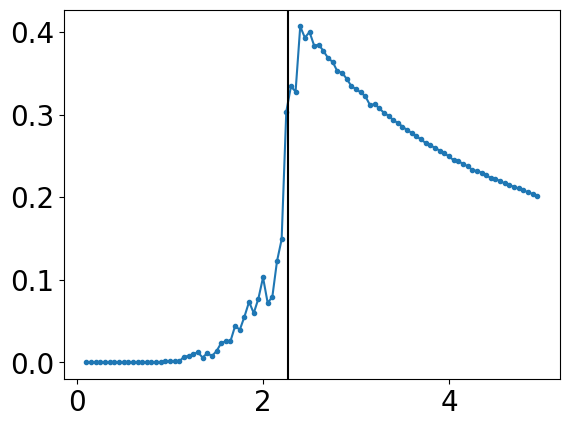

In [303]:
n = 50
n_iter = 200000
n_write = 1000 #na koliko iteracij se zapiše energija
N=10
T = 1
J=-1
H=0
T0=np.arange(0.1,5,0.05)

sus=[]
kapac_=[]
sus_=[]
for T in T0:
    S=np.random.randint(-1,1,(n,n))
    S[S==0] = 1
    i_e=0
    metropolis.counter = 0
    en_metr = E(S,J,H)
    en=np.zeros(n_iter//n_write)
    for i in range(n_iter):
        S,en_metr = metropolis_per(en_metr, S,T,J,H)
        if i % n_write==0:
            en[i_e] = en_metr
            i_e+=1
    a=ising_(n,T)
    sus_.append(susceptibilnost_(a,T))
    sus.append(suscept(magnetizacija(S,n**2),n**2,T))
    kapac_.append(kapaciteta_(a,T))

#plt.plot(T0,sus)
plt.plot(T0,sus_, '.-')
plt.axvline(x=2.27,color='k')

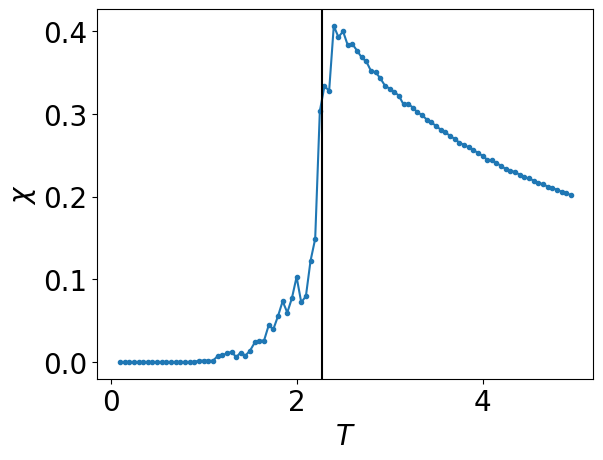

In [307]:
plt.plot(T0,sus_, '.-')
plt.axvline(x=2.27,color='k')
plt.xlabel('$T$')
plt.ylabel('$\chi$')
#plt.savefig('slike/sus_J.pdf',bbox_inches='tight')

# ravnovesje

ravnovesno stanje: -1644.0307692307692, dolžine 65,  6500 iteracij simulacije


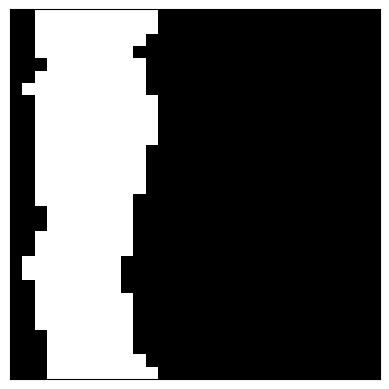

Text(0, 0.5, '$E$')

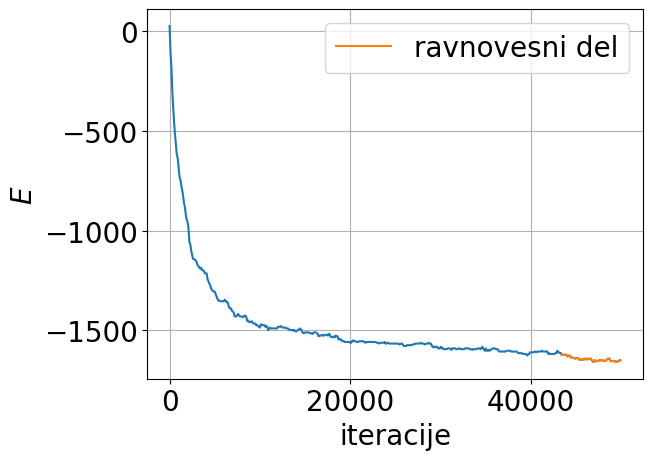

In [12]:
n = 30
n_iter = 50000
n_write = 100 #na koliko iteracij se zapiše energija
T = 1
J=1
H=0

fig, ax = plt.subplots(1,1)
energija_metropolis_per=np.zeros(n_iter//n_write)
S=np.random.randint(-1,1,(n,n))
S[S==0] = 1
i_e=0
metropolis.counter = 0
en_metr = E(S,J,H)
for i in range(n_iter):
    S,en_metr = metropolis_per(en_metr, S,T,J,H)
    if i % n_write==0:
        #energija_per[i_e] = E(S,J,H)
        energija_metropolis_per[i_e] = en_metr
        i_e+=1
i=1
Ei0 = energija_metropolis_per[-1]
Ei1 = energija_metropolis_per[-1*(i+1)]
E_ravn=[]
while abs((Ei1 - Ei0)/Ei0) < 0.02 and i<len(energija_metropolis_per)-1:
    #print((Ei1 - Ei0)/Ei0, Ei0, Ei1)
    E_ravn.append(Ei1)
    i+=1
    Ei1 = energija_metropolis_per[-1*i]
E_ravn=E_ravn[1::]
if len(E_ravn)>=10:
    print(f'ravnovesno stanje: {np.average(E_ravn)}, dolžine {len(E_ravn)}, ', len(E_ravn)*n_write,'iteracij simulacije')
else:
    print(f'ni ravnovesja: {len(E_ravn)}, E={np.average(E_ravn)}')
n_rej = metropolis.counter
ax.imshow(S, cmap='gray', interpolation='nearest')
plt.xticks([])
plt.yticks([])
#plt.title(f'periodični RP')
#plt.savefig(f'slike/metopolis_E.pdf', bbox_inches='tight')
plt.show()

x_val=[n_write*i for i in range(n_iter//n_write)]
plt.plot(x_val, energija_metropolis_per)
plt.plot(x_val[-len(E_ravn)-1:-1], np.flip(E_ravn),label='ravnovesni del')
plt.legend()
plt.grid()
plt.xlabel('iteracije')
plt.ylabel('$E$')

# ravnovesje - ni OK

In [152]:
def ravnovesna_E_test(n,n_iter,n_write,T,J,H):
    S=np.random.randint(-1,1,(n,n))
    S[S==0] = 1
    metropolis.counter = 0
    en_metr = E(S,J,H)
    E_ravn=[]
    E_avg = 0
    i=1
    S,en_metr = metropolis_per(en_metr, S,T,J,H)
    E_vse=[en_metr]
    while abs((en_metr - E_avg)/E_avg) > 0.05 and i<n_iter:
        S,en_metr = metropolis_per(en_metr, S,T,J,H)
        if i % n_write==0:
            E_vse.append(en_metr)
            E_avg = np.average(E_vse)
        i+=1
    i_e=0
    for j in range(1000):
        S,en_metr = metropolis_per(en_metr, S,T,J,H)
        if j % n_write==0:
            E_ravn.append(en_metr)
        i_e+=1
    #E_ravn=E_ravn[1::]
    if i==n_iter-1 or max(abs(E_ravn - np.average(E_ravn)/np.average(E_ravn))) > 0.05:
        print(f'ni ravnovesno: razlika {max(abs(E_ravn - np.average(E_ravn)))}')
    else:
        print('ravnovesje', np.average(E_ravn), max(abs(E_ravn - np.average(E_ravn))), i-n_iter)
    return E_ravn
def ravnovesna_E(n,n_iter,n_write,T,J,H):
    energija_metropolis_per=np.zeros(n_iter//n_write)
    S=np.random.randint(-1,1,(n,n))
    S[S==0] = 1
    i_e=0
    metropolis.counter = 0
    en_metr = E(S,J,H)
    for i in range(n_iter):
        S,en_metr = metropolis_per(en_metr, S,T,J,H)
        if i % n_write==0:
            energija_metropolis_per[i_e] = en_metr
            i_e+=1
    i=1
    st=100 #step za povprečenje
    Ei0 = np.average(energija_metropolis_per[-st*i:-1])
    Ei1 = np.average(energija_metropolis_per[-st*(i+1):-st*i])
    E_ravn=[]
    while abs((Ei1 - Ei0)/Ei0) < 0.05 and i<len(energija_metropolis_per)-1:
        E_ravn.append(Ei1)
        i+=1
        Ei1 = np.average(energija_metropolis_per[-st*(i+1):-st*i])
    E_ravn=E_ravn[1:st*i]
    if len(E_ravn)>=3:
        print(f'ravnovesno stanje: {np.average(E_ravn)}, dolžine {len(E_ravn)}, ', len(E_ravn)*n_write,'iteracij simulacije')
        return E_ravn, energija_metropolis_per
    else:
        print(f'ni ravnovesja: {len(E_ravn)}, E={np.average(E_ravn)}')

2
ni ravnovesja: 2, E=-3790.38


TypeError: cannot unpack non-iterable NoneType object

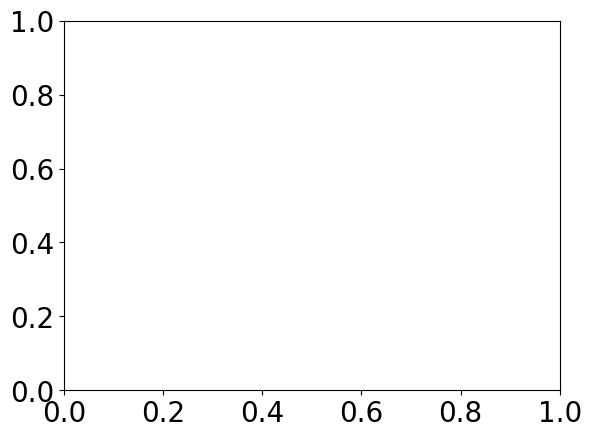

In [ ]:
n = 50
n_iter = 120000
n_write = 100 #na koliko iteracij se zapiše energija
T0 = np.flip(np.arange(0.1,4,0.5))
T0=[2]
J=1
H=0

E_r = []
E_vse=[]
fig, ax = plt.subplots(1,1)
cmap = plt.get_cmap('viridis')
for i in range(len(T0)):
    T=T0[i]
    print(T)
    Ei,E_vse_i=ravnovesna_E(n,n_iter,n_write,T,J,H)
    E_r.append(Ei)
    E_vse.append(E_vse_i)

    # color_i = cmap(T0[i] / max(T0))
    # x_val=[n_write*i for i in range(len(Ei))]
    # ax.plot(x_val, Ei,color=color_i)
    #ax.plot(x_val[-len(Ei)-1:-1], np.flip(Ei),label='ravnovesni del',color=color_i)
# sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=min(T0), vmax=max(T0)))
# sm.set_array([])
# cbar = fig.colorbar(sm, ax=ax, orientation='vertical', label='T')
# cbar.ax.yaxis.set_label_coords(5, 0.5)
# #plt.legend()
# plt.xlabel('iteracije')
# plt.ylabel('$E$')

x_val=[n_write*i for i in range(n_iter//n_write)]
for i in range(len(E_vse)):
    color_i = cmap(T0[i] / max(T0))
    ax.plot(x_val, E_vse[i],color=color_i)
    ax.plot(x_val[-len(E_r[i])-1:-1], np.flip(E_r[i]),'r-')
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=min(T0), vmax=max(T0)))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', label='T')
cbar.ax.yaxis.set_label_coords(5, 0.5)
ax.plot(0,0,'r',label='ravnovesno stanje')
plt.legend()
plt.show()

for i in range(len(Ei)):
    plt.plot(T0[i], np.average(Ei[i]), '.-')
plt.vlines(2.269185,0,1,'k')